# Análisis: ¿el "buen precio" Spot fue realmente un buen negocio?

Este notebook parte de los archivos generados por `limpieza_datos.ipynb`.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

os.makedirs("graficos", exist_ok=True)
pd.set_option("display.float_format", "{:,.2f}".format)

In [ ]:
# Parámetros
CASTIGO_VENCIMIENTO = 0.50   # % del precio que se pierde si el lote supera su vida útil
DIAS_PERIODO = 274           # días entre el 1 de enero y el 30 de septiembre de 2024

In [ ]:
datos = pd.read_excel("datos_limpios/compras_limpias.xlsx")
capacidad = pd.read_excel("datos_limpios/capacidad_centros.xlsx")

df = datos[datos["usar_en_analisis"]].copy()
df["BuyingMode"].value_counts()

Filas totales: 165
Filas para el análisis: 134


Contract    82
Spot        52
Name: BuyingMode, dtype: int64

## 2. Costo total por unidad (landed cost)

In [ ]:
df["transporte_unidad"] = df["TransportCostUSD"] / df["OrderQuantity"]
df["almacenamiento_unidad"] = df["StorageCostPerUnitPerDay"].fillna(0) * df["dias_almacenamiento"]
df["vencimiento_unidad"] = np.where(df["supera_vida_util"], CASTIGO_VENCIMIENTO * df["UnitPriceUSD"], 0)

df["costo_total_unidad"] = (df["UnitPriceUSD"] + df["transporte_unidad"]
                            + df["almacenamiento_unidad"] + df["vencimiento_unidad"])

df["pct_vida_util_usada"] = df["DaysInStorage"] / df["ShelfLifeDays"]

df[["POSampleID", "MaterialName", "BuyingMode", "UnitPriceUSD", "transporte_unidad",
    "almacenamiento_unidad", "vencimiento_unidad", "costo_total_unidad"]].head(10)

,POSampleID,MaterialName,BuyingMode,UnitPriceUSD,transporte_unidad,almacenamiento_unidad,vencimiento_unidad,costo_total_unidad
0,PO10001-P,Enzyme Complex,Contract,26.67,0.54,1.19,0.00,28.40
1,PO10002-P,Crude Palm Oil,Spot,24.99,1.00,4.84,12.49,43.32
2,PO10003-P,Yellow Corn,Contract,31.99,1.16,0.94,0.00,34.10
3,PO10004-P,Soy Oil,Spot,4.64,0.36,3.26,2.32,10.58
4,PO10005-S,Amino Acid Blend,Spot,6.54,0.48,9.21,3.27,19.50
5,PO10006-P,Inbound Freight - Truck,Contract,37.53,1.28,0.00,0.00,38.81
6,PO10007-N,Vitamin Premix,Contract,29.71,0.86,1.23,0.00,31.80
7,PO10008-P,Yellow Corn,Contract,33.20,0.71,1.38,0.00,35.29
8,PO10009-P,Gearbox Seal Kit,Contract,8.83,0.19,0.20,0.00,9.22
9,PO10010-P,Bearing Assembly,Contract,21.24,0.59,0.24,0.00,22.07


### Estructura de costos: ticket promedio categoría y modo de compra

In [ ]:
estructura = df.groupby(["Category", "BuyingMode"]).agg(
    ordenes=("POSampleID", "count"),
    precio=("UnitPriceUSD", "median"),
    transporte=("transporte_unidad", "median"),
    almacenamiento=("almacenamiento_unidad", "median"),
    vencimiento=("vencimiento_unidad", "median"),
    costo_total=("costo_total_unidad", "median"),
    dias_bodega=("DaysInStorage", "median"),
    lotes_vencidos=("supera_vida_util", "sum"),
)
estructura

ordenes  precio  transporte  almacenamiento  \
Category           BuyingMode                                                
Logistics Services Contract         10   34.99        0.90            0.00   
                   Spot             11   30.61        2.08            0.00   
MRO / Spare Parts  Contract         30   22.23        0.66            0.23   
                   Spot             10   16.75        0.87            0.84   
Packaging          Contract          8   15.25        0.49            0.21   
                   Spot             14   15.55        1.14            0.58   
Raw Materials      Contract         34   26.33        0.59            1.21   
                   Spot             17   15.00        0.89            5.35   

                               vencimiento  costo_total  dias_bodega  \
Category           BuyingMode                                          
Logistics Services Contract           0.00        35.89        19.00   
                   Spot               0.00        32.72       104.00   
MRO / Spare Parts  Contract           0.00        23.09        25.00   
                   Spot               0.00        18.87       107.50   
Packaging          Contract           0.00        15.98        27.50   
                   Spot               0.00        17.40       144.50   
Raw Materials      Contract           0.00        27.51        24.00   
                   Spot               3.44        19.50       116.00   

                               lotes_vencidos  
Category           BuyingMode                  
Logistics Services Contract                 0  
                   Spot                     0  
MRO / Spare Parts  Contract                 0  
                   Spot                     0  
Packaging          Contract                 0  
                   Spot                     0  
Raw Materials      Contract                 1  
                   Spot                    14

Primera lectura: en todas las categorías Spot tiene un **precio** menor, pero los lotes Spot se quedan en
bodega unas 4 veces más tiempo (~110 días contra ~25). En materias primas eso hace que el almacenamiento y el
vencimiento sean más caros que el descuento.

## 3. Comparación Spot vs. Contrato

**Línea base:** para cada material, la **mediana del costo total por unidad de sus compras por contrato**.
Es "lo que habría costado comprar ese material por el proceso normal".

Para cada compra Spot calculo:
- **Ahorro en precio** = precio contrato (mediana) − precio Spot → lo que ve el comprador
- **Ahorro real** = costo total contrato (mediana) − costo total Spot → lo que realmente se ahorró

In [ ]:
base_contrato = (df[df["BuyingMode"] == "Contract"]
                 .groupby("MaterialCode")
                 .agg(precio_contrato=("UnitPriceUSD", "median"),
                      costo_total_contrato=("costo_total_unidad", "median"))
                 .reset_index())

spot = df[df["BuyingMode"] == "Spot"].merge(base_contrato, on="MaterialCode", how="left")

# Algunos materiales solo se compraron en Spot: no tienen con qué compararse
print("Compras Spot sin contratos:")
print(spot[spot["costo_total_contrato"].isna()][["POSampleID", "MaterialName"]])
spot = spot[spot["costo_total_contrato"].notna()].copy()
print("\nCompras Spot comparables:", len(spot))

Compras Spot sin línea base de contrato:
   POSampleID        MaterialName
3   PO10011-N  PP Woven Bags 25kg
6   PO10018-P  Corrugated Cartons
25  PO10083-N  Corrugated Cartons
38  PO10131-P  PP Woven Bags 25kg

Compras Spot comparables: 48


In [ ]:
spot["ahorro_precio_unidad"] = spot["precio_contrato"] - spot["UnitPriceUSD"]
spot["ahorro_real_unidad"] = spot["costo_total_contrato"] - spot["costo_total_unidad"]

spot["ahorro_precio_usd"] = spot["ahorro_precio_unidad"] * spot["OrderQuantity"]
spot["ahorro_real_usd"] = spot["ahorro_real_unidad"] * spot["OrderQuantity"]

spot["ahorro_precio_pct"] = spot["ahorro_precio_unidad"] / spot["precio_contrato"]
spot["ahorro_real_pct"] = spot["ahorro_real_unidad"] / spot["costo_total_contrato"]

spot["buen_negocio"] = spot["ahorro_real_unidad"] > 0

### Resultado por categoría

In [ ]:
resumen = spot.groupby("Category").agg(
    compras_spot=("POSampleID", "count"),
    descuento_precio_mediana=("ahorro_precio_pct", "median"),
    ahorro_real_mediana=("ahorro_real_pct", "median"),
    ahorro_precio_usd=("ahorro_precio_usd", "sum"),
    ahorro_real_usd=("ahorro_real_usd", "sum"),
    buenos_negocios=("buen_negocio", "sum"),
    lotes_vencidos=("supera_vida_util", "sum"),
)
resumen.loc["TOTAL"] = [len(spot), spot["ahorro_precio_pct"].median(), spot["ahorro_real_pct"].median(),
                        spot["ahorro_precio_usd"].sum(), spot["ahorro_real_usd"].sum(),
                        spot["buen_negocio"].sum(), spot["supera_vida_util"].sum()]
resumen

,compras_spot,descuento_precio_mediana,ahorro_real_mediana,ahorro_precio_usd,ahorro_real_usd,buenos_negocios,lotes_vencidos
Category,,,,,,,
Logistics Services,11.00,0.12,0.08,"47,008.39","33,445.33",9.00,0.00
MRO / Spare Parts,10.00,0.18,0.13,"51,147.82","38,468.46",10.00,0.00
Packaging,10.00,0.13,0.07,"40,175.62","26,071.81",8.00,0.00
Raw Materials,17.00,0.18,-0.41,"65,695.29","-158,359.40",3.00,14.00
TOTAL,48.00,0.16,0.06,"204,027.11","-60,373.81",30.00,14.00


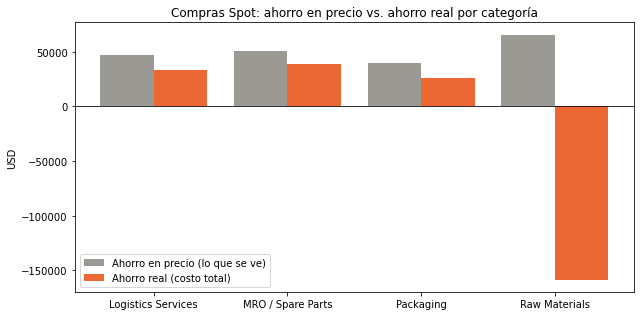

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(resumen) - 1)          # sin la fila TOTAL
r = resumen.drop("TOTAL")

ax.bar(x - 0.2, r["ahorro_precio_usd"], width=0.4, label="Ahorro en precio (lo que se ve)", color="#9a9994")
ax.bar(x + 0.2, r["ahorro_real_usd"], width=0.4, label="Ahorro real (costo total)", color="#eb6834")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(x)
ax.set_xticklabels(r.index)
ax.set_ylabel("USD")
ax.set_title("Compras Spot: ahorro en precio vs. ahorro real por categoría")
ax.legend()
plt.tight_layout()
plt.savefig("graficos/ahorro_por_categoria.png", dpi=150)
plt.show()